# Part F: Ensemble Model Development

This notebook compares the tuned models from Part E and tests soft-voting ensembles using **two base models at a time**. The main goal is to improve recall while keeping accuracy at a reasonable level.

All comparisons use the validation dataset. The saved models are reused without retraining. The test dataset is reserved for Part G.

## 1. Load the models and validation data

Use the same processed validation dataset and saved models from Part E.

In [1]:
# Load the saved models and validation data from Google Drive.
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score,
    average_precision_score
)
from google.colab import drive

# Set up Google Drive paths
ROOT = Path("/content/drive/MyDrive/ML_Group")

if not (ROOT / "validation_dataset.csv").exists():
    drive.mount("/content/drive")

BASE = ROOT / "Part_E_Results"
OUT = ROOT / "Part_F_Results"
OUT.mkdir(parents=True, exist_ok=True)

# Paths to the seven saved models from Part E
model_paths = {
    "R1 Logistic Regression":
        BASE / "saved_models/logistic_regression_round1.joblib",
    "R1 Random Forest":
        BASE / "saved_models/random_forest_round1.joblib",
    "R1 Histogram Gradient Boosting":
        BASE / "saved_models/histogram_gradient_boosting_round1.joblib",
    "R2 Logistic Regression":
        BASE / "Round_2/saved_models/logistic_regression_round2.joblib",
    "R2 Histogram Gradient Boosting":
        BASE / "Round_2/saved_models/histogram_gradient_boosting_round2.joblib",
    "R3 Logistic Regression":
        BASE / "Round_3/saved_models/logistic_regression_round3.joblib",
    "R3 Histogram Gradient Boosting":
        BASE / "Round_3/saved_models/histogram_gradient_boosting_round3.joblib",
}

# Load the processed validation dataset
validation = pd.read_csv(ROOT / "validation_dataset.csv")

X_val = validation.drop(columns="target")
y_val = validation["target"].astype(int).to_numpy()

print("Validation rows:", len(y_val))
print("Charged-off loans:", int(y_val.sum()))


Mounted at /content/drive
Validation rows: 45302
Charged-off loans: 7037


## 2. Compare the seven tuned models

The models are compared at the same **0.50 threshold**. Average Precision and ROC-AUC measure ranking performance, while recall and F2 help assess charge-off detection. Some Round 3 models use different operating thresholds, so this is a common-threshold comparison rather than their final tuned performance.

Evaluated: R1 Logistic Regression
Evaluated: R1 Random Forest
Evaluated: R1 Histogram Gradient Boosting
Evaluated: R2 Logistic Regression
Evaluated: R2 Histogram Gradient Boosting
Evaluated: R3 Logistic Regression
Evaluated: R3 Histogram Gradient Boosting


,AP Rank,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average Precision
0,1,R3 Histogram Gradient Boosting,0.5,0.7508,0.2931,0.4283,0.3481,0.3921,0.6976,0.2868
1,2,R1 Histogram Gradient Boosting,0.5,0.6263,0.2437,0.6683,0.3572,0.4956,0.6976,0.2861
2,3,R2 Histogram Gradient Boosting,0.5,0.6269,0.2438,0.6672,0.3572,0.4952,0.6972,0.2860
3,4,R1 Random Forest,0.5,0.6853,0.2653,0.5799,0.3640,0.4687,0.6975,0.2847
4,5,R3 Logistic Regression,0.5,0.8435,0.4201,0.0190,0.0364,0.0235,0.6947,0.2825
5,6,R2 Logistic Regression,0.5,0.6335,0.2458,0.6574,0.3578,0.4925,0.6946,0.2820
6,7,R1 Logistic Regression,0.5,0.6335,0.2458,0.6572,0.3578,0.4924,0.6945,0.2819


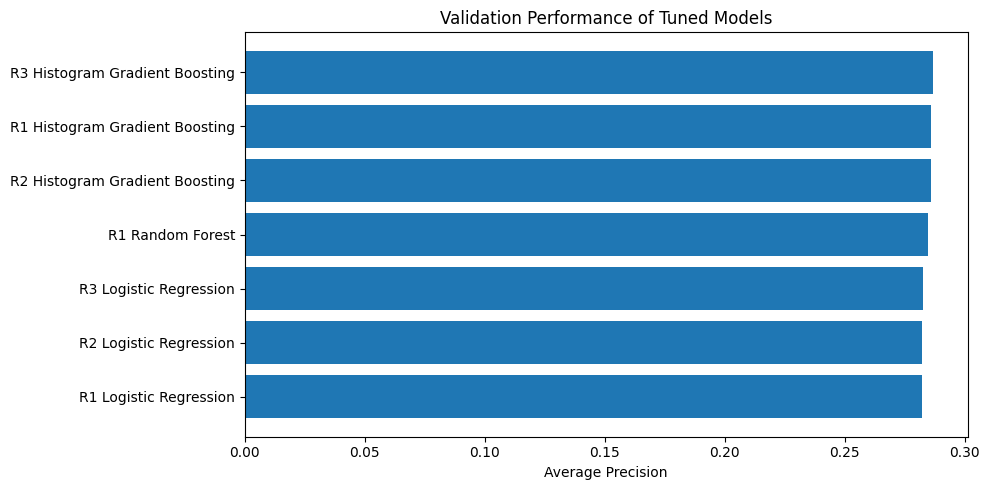

In [2]:

# Calculate performance metrics for a model
def evaluate(name, probabilities, threshold=0.50):
    predicted = (probabilities >= threshold).astype(int)

    return {
        "Model": name,
        "Threshold": round(float(threshold), 3),
        "Accuracy": accuracy_score(y_val, predicted),
        "Precision": precision_score(
            y_val, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predicted, zero_division=0
        ),
        "F1": f1_score(
            y_val, predicted, zero_division=0
        ),
        "F2": fbeta_score(
            y_val, predicted, beta=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(
            y_val, probabilities
        )
    }


scores = {}
rows = []

# Load each saved model and predict on validation data
for name, path in model_paths.items():
    model = joblib.load(path)

    # Keep the same feature order used during training
    if hasattr(model, "feature_names_in_"):
        features = list(model.feature_names_in_)
    else:
        features = list(X_val.columns)

    # Get the probability of class 1 (Charged Off)
    positive_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(
        X_val[features]
    )[:, positive_index]

    scores[name] = probabilities
    rows.append(evaluate(name, probabilities))

    print("Evaluated:", name)

# Rank models by Average Precision
comparison = pd.DataFrame(rows)
comparison = comparison.sort_values(
    "Average Precision", ascending=False
).reset_index(drop=True)

comparison.insert(
    0, "AP Rank", np.arange(1, len(comparison) + 1)
)

display(comparison.round(4))

# Save the comparison table
comparison.to_csv(
    OUT / "seven_model_performance_comparison.csv",
    index=False
)

# Save probabilities for later ensemble experiments
predictions = pd.DataFrame({"actual": y_val})

for name, prob in scores.items():
    predictions[f"{name}_prob"] = prob
    predictions[f"{name}_pred"] = (
        prob >= 0.50
    ).astype(int)

predictions.to_csv(
    OUT / "seven_model_validation_predictions.csv",
    index=False
)

# Plot Average Precision for all seven models
plot_data = comparison.sort_values("Average Precision")

plt.figure(figsize=(10, 5))
plt.barh(
    plot_data["Model"],
    plot_data["Average Precision"]
)

plt.xlabel("Average Precision")
plt.title("Validation Performance of Tuned Models")
plt.tight_layout()

plt.savefig(
    OUT / "seven_model_ap_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 3. Compare two soft-voting ensembles

We first compare **R3 Logistic Regression + R1 HGB** with **R1 Random Forest + R3 HGB**. Each ensemble averages the two models' predicted probabilities with equal weights. The individual models are included as references.

In [3]:

# Create two ensembles by averaging model probabilities
ensembles = {
    "R3 LR + R1 HGB": (
        scores["R3 Logistic Regression"] +
        scores["R1 Histogram Gradient Boosting"]
    ) / 2,

    "R1 RF + R3 HGB": (
        scores["R1 Random Forest"] +
        scores["R3 Histogram Gradient Boosting"]
    ) / 2
}

# Include the individual models for comparison
reference_names = [
    "R3 Logistic Regression",
    "R1 Histogram Gradient Boosting",
    "R1 Random Forest",
    "R3 Histogram Gradient Boosting"
]

references = {
    name: scores[name] for name in reference_names
}

# Evaluate all models at threshold 0.50
fixed_results = pd.DataFrame([
    evaluate(name, prob)
    for name, prob in {**references, **ensembles}.items()
])

print("Comparison at threshold 0.50:")
display(fixed_results.round(4))

# Save the comparison
fixed_results.to_csv(
    OUT / "two_ensemble_fixed_threshold_comparison.csv",
    index=False
)

Comparison at threshold 0.50:


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average Precision
0,R3 Logistic Regression,0.5,0.8435,0.4201,0.0190,0.0364,0.0235,0.6947,0.2825
1,R1 Histogram Gradient Boosting,0.5,0.6263,0.2437,0.6683,0.3572,0.4956,0.6976,0.2861
2,R1 Random Forest,0.5,0.6853,0.2653,0.5799,0.3640,0.4687,0.6975,0.2847
3,R3 Histogram Gradient Boosting,0.5,0.7508,0.2931,0.4283,0.3481,0.3921,0.6976,0.2868
4,R3 LR + R1 HGB,0.5,0.8168,0.3493,0.2082,0.2609,0.2265,0.6980,0.2859
5,R1 RF + R3 HGB,0.5,0.7241,0.2822,0.5031,0.3616,0.4350,0.6989,0.2874


## 4. Compare combinations at 70% minimum accuracy

We also test **R1 LR + R3 HGB**. For each pair, we try different voting weights and thresholds, then find the highest recall with at least 70% accuracy. This is a validation-based selection step, so its best result may be optimistic.

Best recall with accuracy >= 73%:


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average Precision
0,R1 RF + R3 HGB,0.51,0.7344,0.2864,0.4761,0.3576,0.4204,0.6989,0.2874
1,R3 LR + R1 HGB,0.40,0.7356,0.2850,0.4654,0.3535,0.4131,0.6980,0.2859


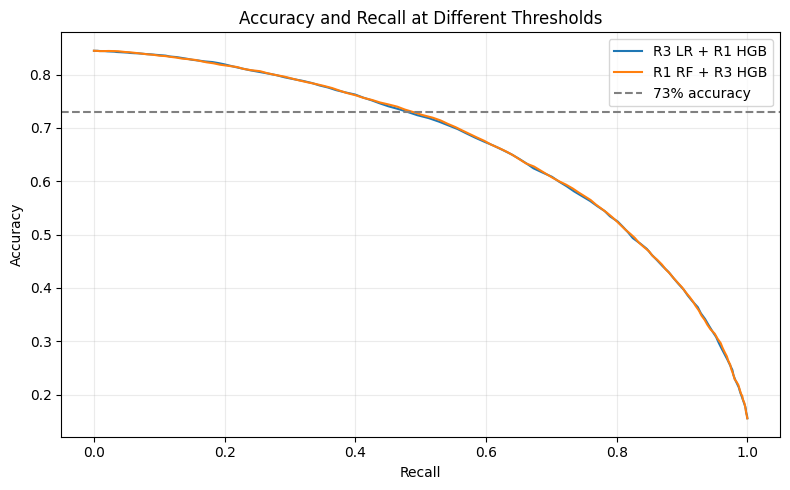

In [4]:
# Test thresholds from 0.05 to 0.95
thresholds_73 = np.linspace(0.05, 0.95, 181)

rows = []

for name, prob in ensembles.items():
    for threshold in thresholds_73:
        rows.append(
            evaluate(name, prob, threshold)
        )

threshold_results = pd.DataFrame(rows)

# Keep results with accuracy of at least 73%
min_accuracy = 0.73

eligible = threshold_results[
    threshold_results["Accuracy"] >= min_accuracy
]

# Find the highest recall for each ensemble
best_73 = (
    eligible.sort_values(
        ["Recall", "F2", "Accuracy"],
        ascending=False
    )
    .groupby("Model", as_index=False)
    .first()
)

print("Best recall with accuracy >= 73%:")
display(best_73.round(4))

# Save threshold comparison results
threshold_results.to_csv(
    OUT / "two_ensemble_threshold_comparison.csv",
    index=False
)

best_73.to_csv(
    OUT / "two_ensemble_recall_accuracy_results.csv",
    index=False
)

# Save both ensemble probability columns
ensemble_predictions = pd.DataFrame({
    "actual": y_val
})

for name, prob in ensembles.items():
    ensemble_predictions[f"{name}_prob"] = prob

ensemble_predictions.to_csv(
    OUT / "two_ensemble_validation_predictions.csv",
    index=False
)

# Plot accuracy against recall
plt.figure(figsize=(8, 5))

for name in ensembles:
    subset = threshold_results[
        threshold_results["Model"] == name
    ]

    plt.plot(
        subset["Recall"],
        subset["Accuracy"],
        label=name
    )

plt.axhline(
    min_accuracy,
    linestyle="--",
    color="gray",
    label="73% accuracy"
)

plt.xlabel("Recall")
plt.ylabel("Accuracy")
plt.title("Accuracy and Recall at Different Thresholds")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUT / "ensemble_accuracy_recall_tradeoff.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 5. Final ensemble

**Selected models:** R1 Random Forest and R3 Histogram Gradient Boosting.

**Method:** Equal-weight soft voting (0.50 / 0.50).

**Threshold:** 0.480, selected on validation data to prioritise recall while keeping accuracy above 70%.

The two models use different methods: Random Forest uses bagging, while Histogram Gradient Boosting uses boosting. Logistic Regression was not selected because the RF + HGB combination gave slightly better recall and F2 in the tested comparisons.

The selected settings are fixed here. Part G will evaluate them once on the untouched test dataset.

In [5]:
# Each combination contains exactly two base model families
pairs = {
    "RF R1 + HGB R3": (
        "R1 Random Forest",
        "R3 Histogram Gradient Boosting"
    ),
    "LR R3 + HGB R1": (
        "R3 Logistic Regression",
        "R1 Histogram Gradient Boosting"
    ),
    "LR R1 + HGB R3": (
        "R1 Logistic Regression",
        "R3 Histogram Gradient Boosting"
    )
}

rows = []

# Try different weights and classification thresholds
for pair_name, (first, second) in pairs.items():
    for weight in np.arange(0.2, 0.81, 0.1):

        # Combine the two models' predicted probabilities
        prob = (
            weight * scores[first] +
            (1 - weight) * scores[second]
        )

        for threshold in np.arange(0.10, 0.801, 0.005):
            result = evaluate(pair_name, prob, threshold)

            result["First Model Weight"] = round(
                float(weight), 2
            )
            result["Second Model Weight"] = round(
                float(1 - weight), 2
            )

            rows.append(result)

search_results = pd.DataFrame(rows)

# Only keep settings with accuracy >= 70%
eligible = search_results[
    search_results["Accuracy"] >= 0.70
]

# Find the highest recall for each combination
best_70 = (
    eligible.sort_values(
        ["Recall", "Accuracy", "F2"],
        ascending=False
    )
    .groupby("Model", as_index=False)
    .first()
    .sort_values("Recall", ascending=False)
)

print("Best recall with accuracy >= 70%:")
display(best_70.round(4))

# Check whether any setting also reaches 60% recall
meets_both = eligible[
    eligible["Recall"] >= 0.60
]

print("\nCombinations with >=70% accuracy and >=60% recall:")

if meets_both.empty:
    print("None of the tested settings reached both targets.")
else:
    display(
        meets_both.sort_values(
            ["Recall", "Accuracy"],
            ascending=False
        ).head(10).round(4)
    )

# Save all search results and the best settings
search_results.to_csv(
    OUT / "ensemble_70_accuracy_search.csv",
    index=False
)

best_70.to_csv(
    OUT / "ensemble_70_accuracy_best.csv",
    index=False
)

Best recall with accuracy >= 70%:


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average Precision,First Model Weight,Second Model Weight
2,RF R1 + HGB R3,0.480,0.7013,0.2727,0.5536,0.3654,0.4591,0.6989,0.2874,0.5,0.5
0,LR R1 + HGB R3,0.470,0.7015,0.2724,0.5517,0.3647,0.4578,0.6982,0.2869,0.2,0.8
1,LR R3 + HGB R1,0.335,0.7014,0.2719,0.5498,0.3639,0.4565,0.6978,0.2855,0.6,0.4



Combinations with >=70% accuracy and >=60% recall:
None of the tested settings reached both targets.


## 6. Save the final ensemble
We selected RF Round 1 and HGB Round 3 because this combination gave the best recall among the tested ensembles while keeping accuracy above 70%.

The final weights and threshold are fixed for Part G.

In [6]:

# Final ensemble settings selected from validation results
FINAL_MODELS = [
    "R1 Random Forest",
    "R3 Histogram Gradient Boosting"
]

FINAL_WEIGHTS = [0.5, 0.5]
FINAL_THRESHOLD = 0.480

# Equal-weight soft voting
final_prob = (
    FINAL_WEIGHTS[0] * scores[FINAL_MODELS[0]] +
    FINAL_WEIGHTS[1] * scores[FINAL_MODELS[1]]
)

# Evaluate the final ensemble on validation data
final_result = pd.DataFrame([
    evaluate(
        "Final RF + HGB Ensemble",
        final_prob,
        FINAL_THRESHOLD
    )
])

print("Final ensemble validation results:")
display(final_result.round(4))

# Save final performance metrics
final_result.to_csv(
    OUT / "final_ensemble_validation_metrics.csv",
    index=False
)

# Save probabilities and predicted labels
final_predictions = pd.DataFrame({
    "actual": y_val,
    "rf_probability": scores[FINAL_MODELS[0]],
    "hgb_probability": scores[FINAL_MODELS[1]],
    "ensemble_probability": final_prob,
    "ensemble_prediction": (
        final_prob >= FINAL_THRESHOLD
    ).astype(int)
})

final_predictions.to_csv(
    OUT / "final_ensemble_validation_predictions.csv",
    index=False
)

# Save the ensemble settings for Part G
config = {
    "method": "equal_weight_soft_voting",
    "model_paths": [
        str(model_paths[name].relative_to(ROOT))
        for name in FINAL_MODELS
    ],
    "model_names": FINAL_MODELS,
    "weights": FINAL_WEIGHTS,
    "threshold": FINAL_THRESHOLD,
    "selection_data": "validation",
    "minimum_validation_accuracy": 0.70
}

with open(
    OUT / "final_ensemble_config.json", "w"
) as file:
    json.dump(config, file, indent=2)

print("Final ensemble saved to:", OUT)
print("Test dataset not used.")

Final ensemble validation results:


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC,Average Precision
0,Final RF + HGB Ensemble,0.48,0.7013,0.2727,0.5536,0.3654,0.4591,0.6989,0.2874


Final ensemble saved to: /content/drive/MyDrive/ML_Group/Part_F_Results
Test dataset not used.
